# Training-only unsupervised analysis

Synthetic data only, seed **57**. K-Means, hierarchical clustering, DBSCAN and PCA are **PROVISIONAL / UNVERIFIED** syllabus candidates. Cluster IDs are arbitrary: **they are not LOW/MEDIUM/HIGH ground-truth labels**. Both supervised targets and all identifiers are excluded from fitting.

IQR and z-score threshold analysis runs only with explicit method-specific official verification evidence. In the current project it is skipped, and flags remain blank rather than being called normal. DBSCAN density noise is recorded separately and is not confirmed anomaly truth. No raw rows are removed.

Only train.csv and the split manifest are opened. Validation and test are not analyzed, transformed or fitted. Hierarchical clustering is explicitly limited to a seed-57 2,000-row training sample.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate/'ml-service/data/splits/train.csv').is_file() and (candidate/'AGENTS.md').is_file():
        ROOT=candidate
        break
else:
    raise FileNotFoundError('Run within the Raah repository')
sys.path.insert(0,str(ROOT/'ml-service'))
import pandas as pd
from training.unsupervised import run_analysis
ARTIFACTS=ROOT/'artifacts/unsupervised'
SPLITS=ROOT/'ml-service/data/splits'
inputs={name:hashlib.sha256((SPLITS/name).read_bytes()).hexdigest() for name in ('train.csv','split_manifest.json')}
result,summary=run_analysis(output_dir=ARTIFACTS,findings_path=ROOT/'docs/UNSUPERVISED_FINDINGS.md')
print('Training rows:',summary['fit_rows'],'runs:',len(summary['fit_run_ids']))
print('Features:',summary['features'])
print(result['metrics'].to_string(index=False))
print('Profiles in original units (no target columns):')
print(result['profiles'][['method','cluster_id','rows','profile_status','mean_speed_kmh_mean','queue_length_vehicles_mean','mean_wait_seconds_mean']].round(3).to_string(index=False))
def show(filename):
    path=ARTIFACTS/filename
    if '_raah_emit_png' in globals():
        _raah_emit_png(path)
    else:
        try:
            from IPython.display import Image,display
            display(Image(filename=str(path)))
        except ImportError:
            print('Saved chart:',path)


Training rows: 8712 runs: 18
Features: ['mean_speed_kmh', 'free_flow_speed_kmh', 'vehicle_count', 'queue_length_vehicles', 'mean_wait_seconds', 'incoming_vehicles', 'outgoing_vehicles', 'seconds_in_phase', 'time_of_day', 'gps_sample_count']
      method                 status        fit_status  requested_clusters  effective_nonnoise_clusters  fit_rows  noise_rows  silhouette  silhouette_rows                                                        silhouette_status
      KMeans PROVISIONAL_UNVERIFIED FITTED_TRAIN_ONLY                 3.0                            3      8712           0    0.184828             1500                                                       TRAIN_ONLY_SAMPLED
hierarchical PROVISIONAL_UNVERIFIED FITTED_TRAIN_ONLY                 3.0                            3      2000           0    0.153415             1500                                                       TRAIN_ONLY_SAMPLED
      DBSCAN PROVISIONAL_UNVERIFIED FITTED_TRAIN_ONLY                 NaN     

## K-Means: full training fit, not class labels

Clustering uses standardized ten-dimensional current measurements; the following PCA projection is only a display. k=3 is predeclared, not evidence that there are three true traffic classes. Silhouette uses at most 1,500 seeded training observations.


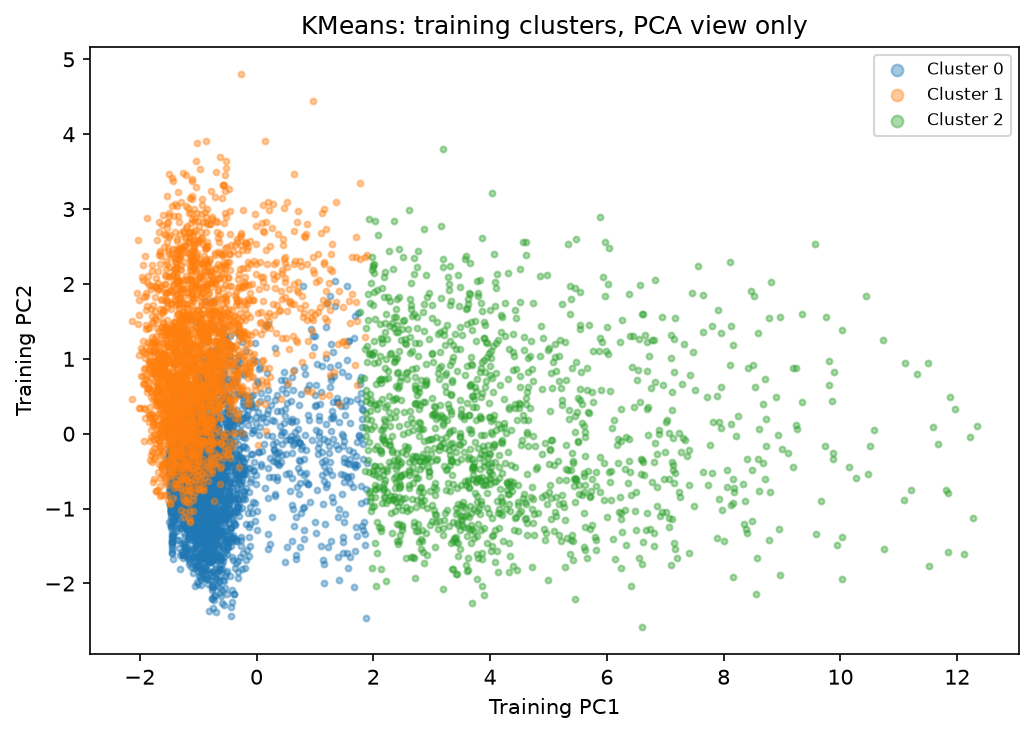

Takeaway: K-Means silhouette is 0.1848 in the standardized feature space. This is a modest geometric separation, not classification accuracy. Three arbitrary cluster IDs must not be relabeled LOW/MEDIUM/HIGH as ground truth.


In [2]:
show('01_KMeans_pca2d.png')
score=result['metrics'].set_index('method').loc['KMeans','silhouette']
print(f'Takeaway: K-Means silhouette is {score:.4f} in the standardized feature space. This is a modest geometric separation, not classification accuracy. Three arbitrary cluster IDs must not be relabeled LOW/MEDIUM/HIGH as ground truth.')


## Hierarchical clustering: disclosed training sample

Ward clustering has quadratic cost. The selected 2,000 training-row indices are retained in the analysis manifest. Blank assignments for other training rows are intentional; no unsupported out-of-sample labels are invented.


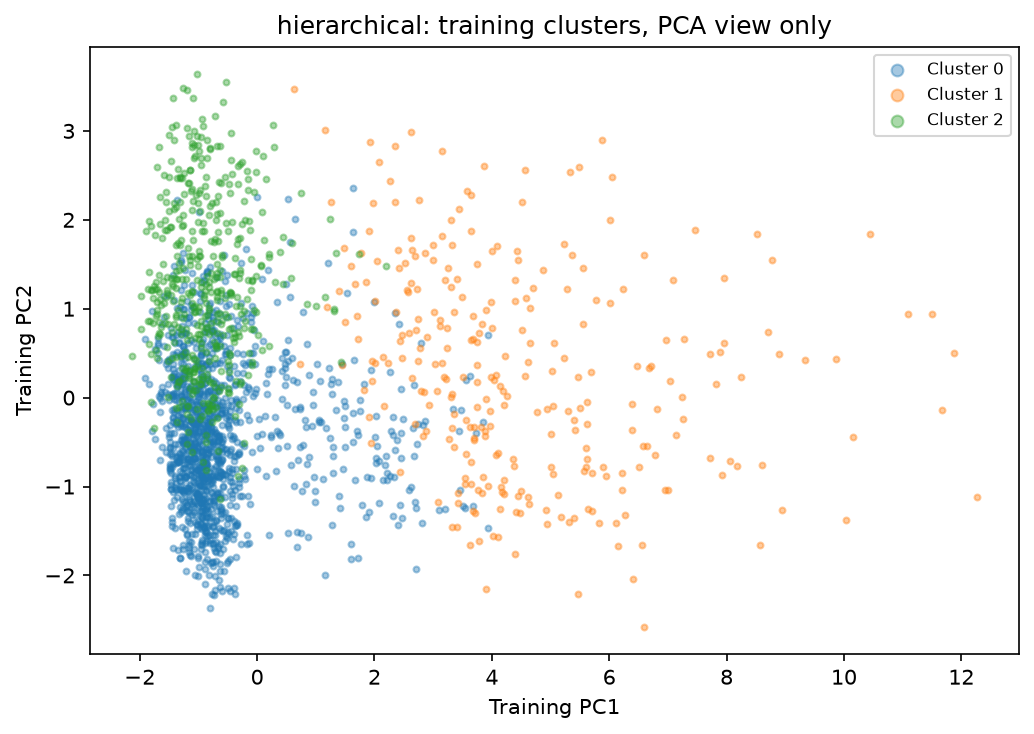

Takeaway: Ward clustering fits 2,000 of 8,712 training rows; silhouette is 0.1534. This sample-specific hierarchy cannot be read as a complete labeling of all training data or proof of independent traffic regimes.


In [3]:
show('02_hierarchical_pca2d.png')
score=result['metrics'].set_index('method').loc['hierarchical','silhouette']
print(f'Takeaway: Ward clustering fits {summary["hierarchical_fit_rows"]:,} of {summary["fit_rows"]:,} training rows; silhouette is {score:.4f}. This sample-specific hierarchy cannot be read as a complete labeling of all training data or proof of independent traffic regimes.')


## DBSCAN: density noise is not confirmed anomaly

Parameters are fixed before inspection (eps=1.2, min_samples=20) on training-standardized features. Noise is omitted from silhouette scoring; treating a single cluster plus noise as two genuine clusters would be misleading.


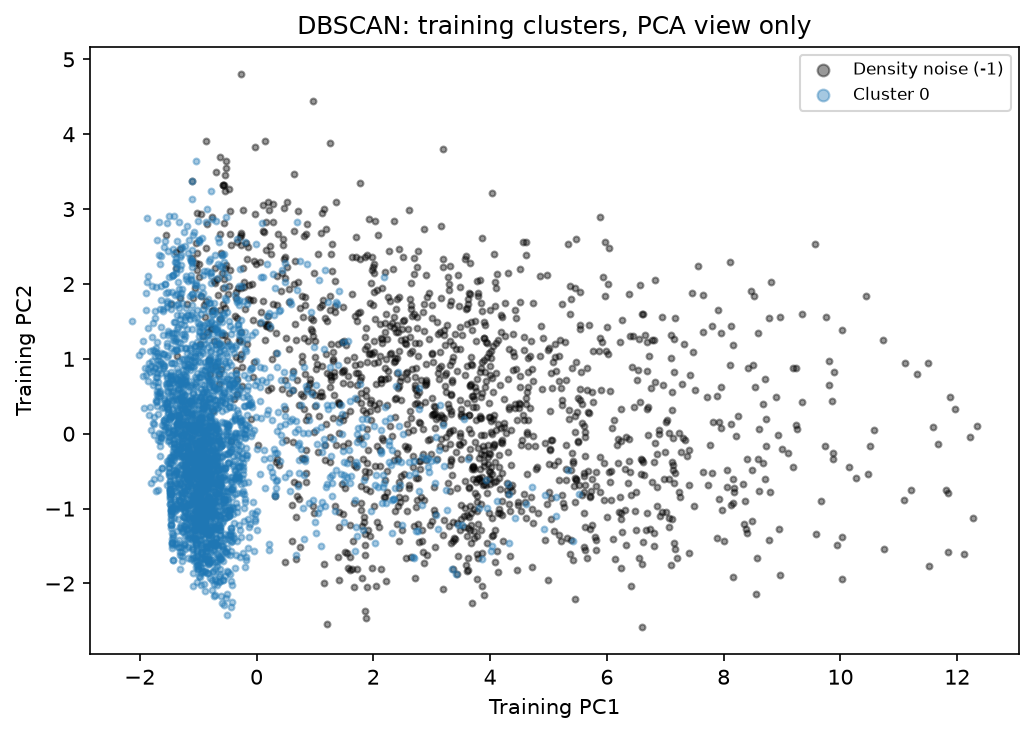

Takeaway: DBSCAN finds 1 non-noise cluster(s) and 1,404 noise rows. Silhouette status: NOT_MEANINGFUL: need >=2 non-noise clusters and fewer clusters than rows. Noise means unassigned at these settings, not true anomaly or a reason to delete observations.


In [4]:
show('03_DBSCAN_pca2d.png')
row=result['metrics'].set_index('method').loc['DBSCAN']
print(f'Takeaway: DBSCAN finds {int(row.effective_nonnoise_clusters)} non-noise cluster(s) and {summary["density_noise_rows"]:,} noise rows. Silhouette status: {row.silhouette_status}. Noise means unassigned at these settings, not true anomaly or a reason to delete observations.')


## PCA 2D view: current queues, not outcome labels

PCA, median imputation and scaling all fit only on training. The color is one current input, queue length; no congestion/future-wait target is used. Correlated count/queue/wait/coverage fields can dominate the geometry.


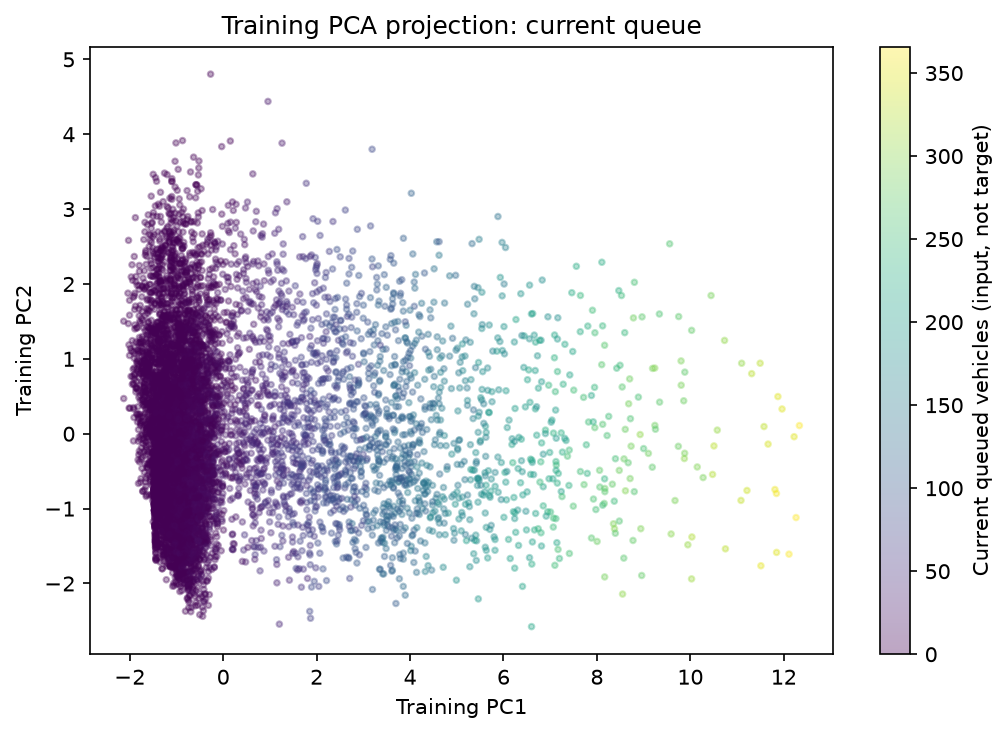

Takeaway: The first two components retain 56.34% of training variance, leaving 43.66% outside this display. Apparent 2D separation and queue color gradients are descriptive, not supervised target agreement or real-road validation.


In [5]:
show('04_PCA_training_2d.png')
share=summary['pca_two_component_variance']
print(f'Takeaway: The first two components retain {100*share:.2f}% of training variance, leaving {100*(1-share):.2f}% outside this display. Apparent 2D separation and queue color gradients are descriptive, not supervised target agreement or real-road validation.')


## Explained variance

The complete component table is saved, not just the first two values. Explained input variance is neither predictive accuracy nor evidence of causal signal-control improvements.


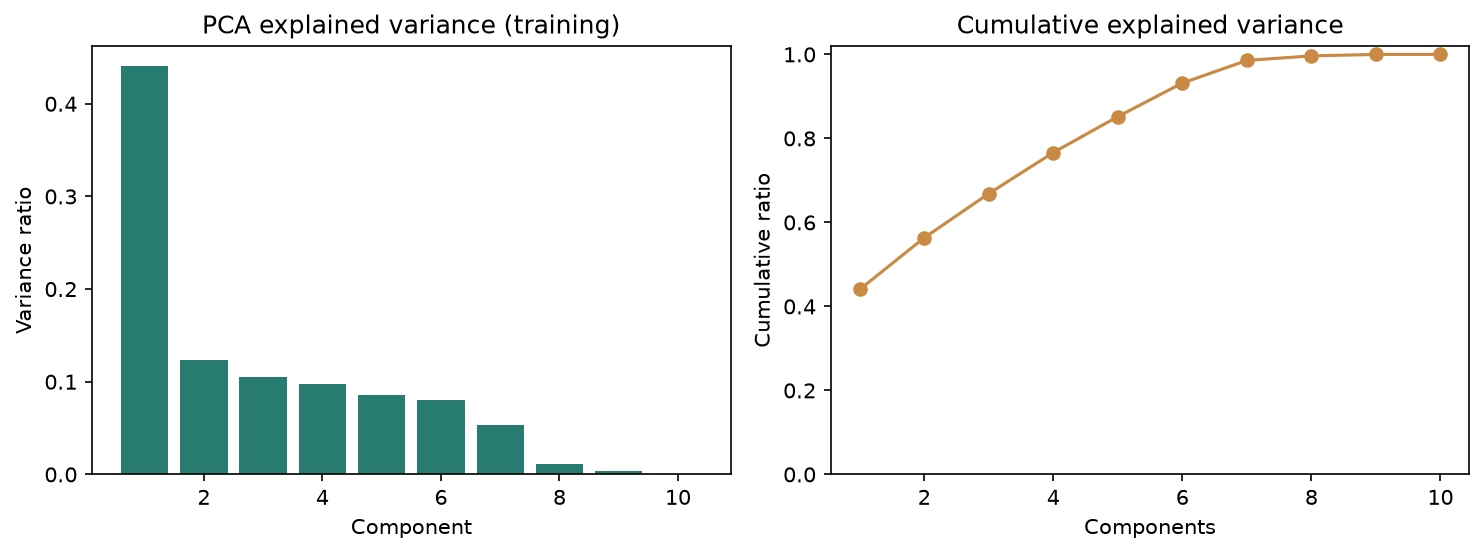

 component  explained_variance_ratio  cumulative_explained_variance
         1                   0.44033                        0.44033
         2                   0.12305                        0.56338
         3                   0.10516                        0.66854
         4                   0.09779                        0.76633
         5                   0.08557                        0.85190
         6                   0.07987                        0.93177
         7                   0.05386                        0.98563
         8                   0.01083                        0.99646
         9                   0.00348                        0.99994
        10                   0.00006                        1.00000
Takeaway: PCA compresses correlated standardized input variation. Retained variance alone does not establish useful congestion prediction; no downstream model is selected or evaluated here.


In [6]:
show('05_PCA_explained_variance.png')
print(result['variance'].round(5).to_string(index=False))
print('Takeaway: PCA compresses correlated standardized input variation. Retained variance alone does not establish useful congestion prediction; no downstream model is selected or evaluated here.')


## Evidence-gated anomaly flags and integrity

Only explicit VERIFIED IQR/z_score entries with official title/version/source and section enable their thresholds. Missing evidence means not evaluated. The current UNVERIFIED outlier topic alone is insufficient. Flags/rationale are saved without modifying source CSVs.


In [7]:
print('Anomaly methods:',summary['anomaly_methods'])
flags=pd.read_csv(ARTIFACTS/'anomaly_flags.csv')
print(flags[['iqr_flag','iqr_status','z_score_flag','z_score_status','density_noise_flag','rationale']].head(3).to_string(index=False))
for name,status in summary['anomaly_methods'].items():
    if status=='SKIPPED_UNVERIFIED':
        field='iqr_flag' if name=='IQR' else 'z_score_flag'
        assert flags[field].isna().all()
assert inputs=={name:hashlib.sha256((SPLITS/name).read_bytes()).hexdigest() for name in inputs}
assert summary['validation_data_opened'] is summary['test_data_opened'] is False
assert not summary['cluster_ids_are_ground_truth'] and not summary['coverage_asserted']
assert len(summary['plots'])==5
print('PASS: training inputs unchanged; held-out CSVs not opened; cluster/noise IDs are not ground truth.')


Anomaly methods: {'IQR': 'SKIPPED_UNVERIFIED', 'z_score': 'SKIPPED_UNVERIFIED'}
 iqr_flag         iqr_status  z_score_flag     z_score_status  density_noise_flag                                                                                                                                                                                    rationale
      NaN SKIPPED_UNVERIFIED           NaN SKIPPED_UNVERIFIED               False IQR: not evaluated; official method-specific permission absent; z_score: not evaluated; official method-specific permission absent; DBSCAN: assigned density cluster, not proof of normality
      NaN SKIPPED_UNVERIFIED           NaN SKIPPED_UNVERIFIED               False IQR: not evaluated; official method-specific permission absent; z_score: not evaluated; official method-specific permission absent; DBSCAN: assigned density cluster, not proof of normality
      NaN SKIPPED_UNVERIFIED           NaN SKIPPED_UNVERIFIED               False IQR: not evaluated; offic